# 平均换手率（TURNAVG）

**行为金融因子 —— 投资者注意力**

$$
\text{TURNAVG} = \frac{1}{m} \sum_{t=1}^{m} \text{TURN}_{i,t}
$$

其中：

* $\text{TURN}_{i,t}$ 为股票 $i$ 在交易日 $t$ 的换手率；
* $m$ 为交易日窗口，一般取为月度（即当月所有交易日）。

## 因子说明

平均换手率（TURNAVG）属于**股票交易活跃度类因子**，通过衡量股票在月度内的平均交易活跃度来反映投资者对该股票的关注程度。股票交易越活跃，说明市场参与者对该股票的买卖意愿越强，投资者对该股票的关注度也就越高。然而，投资者的注意力是有限的，他们更倾向于交易那些引起自己注意的股票。高关注度往往伴随着更多的非理性买入行为，在 A 股市场做多与做空不对称的背景下，这种非理性净买入会推动股价产生短期溢价，进而在未来引发价格反转。

数据：日度换手率

In [1]:
import pandas as pd

from rqdatac import (
    all_instruments,
    get_trading_dates,
    get_turnover_rate,
)


def calculate_turnavg_daily(
    start_date,
    end_date,
    window=20,
    candidate_ids=None,
    batch_size=500,
    output="wide",
):
    """
    平均换手率（TURNAVG）。

    每个交易日 t 使用 [t-window+1, t] 的日换手率均值。

    参数
    ----
    window : int
        滚动交易日窗口，默认 20，约为一个月。

    output : str
        "wide"  : date × order_book_id 宽表，可直接传入 factor_analysis；
        "panel" : [date, order_book_id] 两层索引、单列 TURNAVG。
    """
    if not isinstance(window, int) or window < 1:
        raise ValueError("window 必须是正整数。")

    if output not in ("wide", "panel"):
        raise ValueError('output 仅支持 "wide" 或 "panel"。')

    if candidate_ids is None:
        candidate_ids = (
            all_instruments("CS")["order_book_id"]
            .dropna()
            .drop_duplicates()
            .tolist()
        )
    else:
        candidate_ids = list(
            pd.Index(candidate_ids).dropna().unique()
        )

    if not candidate_ids:
        raise ValueError("candidate_ids 为空。")

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    # 额外获取历史交易日，以保证起始日也能计算完整 20 日均值。
    calendar = pd.DatetimeIndex(
        pd.to_datetime(
            get_trading_dates(
                start_date=start_date - pd.Timedelta(
                    days=max(window * 3, 90)
                ),
                end_date=end_date,
            )
        )
    )

    target_dates = calendar[
        (calendar >= start_date)
        & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("目标区间内没有交易日。")

    first_target_position = calendar.get_loc(target_dates[0])

    if first_target_position < window - 1:
        raise ValueError("历史交易日不足，无法计算完整 TURNAVG。")

    fetch_dates = calendar[
        first_target_position - window + 1:
    ]

    turnover_parts = []

    for start in range(0, len(candidate_ids), batch_size):
        batch_ids = candidate_ids[start:start + batch_size]

        raw = get_turnover_rate(
            order_book_ids=batch_ids,
            start_date=fetch_dates[0],
            end_date=fetch_dates[-1],
            fields="today",
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            turnover = raw["today"].unstack("order_book_id")
        else:
            # 单只股票请求时的兼容处理
            turnover = raw[["today"]].rename(
                columns={"today": batch_ids[0]}
            )

        turnover.index = pd.to_datetime(turnover.index)

        turnover_parts.append(
            turnover.reindex(
                index=fetch_dates,
                columns=batch_ids,
            )
        )

    if not turnover_parts:
        raise RuntimeError("未取得有效换手率数据，请检查接口权限。")

    turnover_wide = pd.concat(turnover_parts, axis=1)
    turnover_wide = turnover_wide.loc[
        :,
        ~turnover_wide.columns.duplicated()
    ]

    turnover_wide = turnover_wide.reindex(
        index=fetch_dates,
        columns=candidate_ids,
    ).astype(float)

    # 截至 t 的过去 window 个交易日平均换手率
    turnavg_wide = turnover_wide.rolling(
        window=window,
        min_periods=window,
    ).mean()

    factor_df = turnavg_wide.reindex(target_dates)
    factor_df.index = pd.DatetimeIndex(factor_df.index)
    factor_df.index.name = "date"
    factor_df.columns.name = "order_book_id"

    if output == "wide":
        return factor_df

    factor_panel = factor_df.stack(dropna=True).to_frame(
        "TURNAVG"
    )
    factor_panel.index.names = ["date", "order_book_id"]

    return factor_panel

In [2]:
turnavg_df = calculate_turnavg_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    window=20,
    candidate_ids=None,
    batch_size=500,
    output="wide",
)

turnavg_df

order_book_id,000001.XSHE,000002.XSHE,000003.XSHE,000004.XSHE,000005.XSHE,000006.XSHE,000007.XSHE,000008.XSHE,000009.XSHE,000010.XSHE,...,688820.XSHG,688825.XSHG,688826.XSHG,688828.XSHG,688835.XSHG,688836.XSHG,688837.XSHG,688981.XSHG,689009.XSHG,990018.XSHG
date,,,,,,,,,,,,,,,,,,,,,
2020-01-02,0.390605,0.925120,NaN,1.802595,0.747180,0.649565,2.029105,1.338860,3.373510,0.359385,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,0.405010,0.947370,NaN,1.826650,0.756765,0.690845,2.025380,1.290970,3.700435,0.359370,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,0.408860,0.974050,NaN,1.859955,0.776410,0.706980,2.041260,1.240475,3.915460,0.353980,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,0.412020,0.944065,NaN,1.883160,0.820630,0.708740,1.872375,1.178470,4.427265,0.411010,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-08,0.419530,0.936060,NaN,1.922410,0.910505,0.727640,1.709720,1.174665,4.841510,0.436175,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-25,0.421360,2.704190,NaN,3.279355,NaN,2.185095,4.732375,1.666760,0.996565,2.364540,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.984280,1.064825,NaN
2025-12-26,0.409820,2.616100,NaN,2.962975,NaN,2.206090,4.626185,1.614255,1.005120,2.231000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.007715,1.101540,NaN
2025-12-29,0.399800,2.512835,NaN,2.705015,NaN,2.182930,4.491275,1.590235,0.961885,2.108235,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.052520,1.077055,NaN


In [3]:
from rqfactor.notebook import factor_analysis

result_factor = factor_analysis(
    f=turnavg_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)

result_factor.show()

Loading BokehJS ...

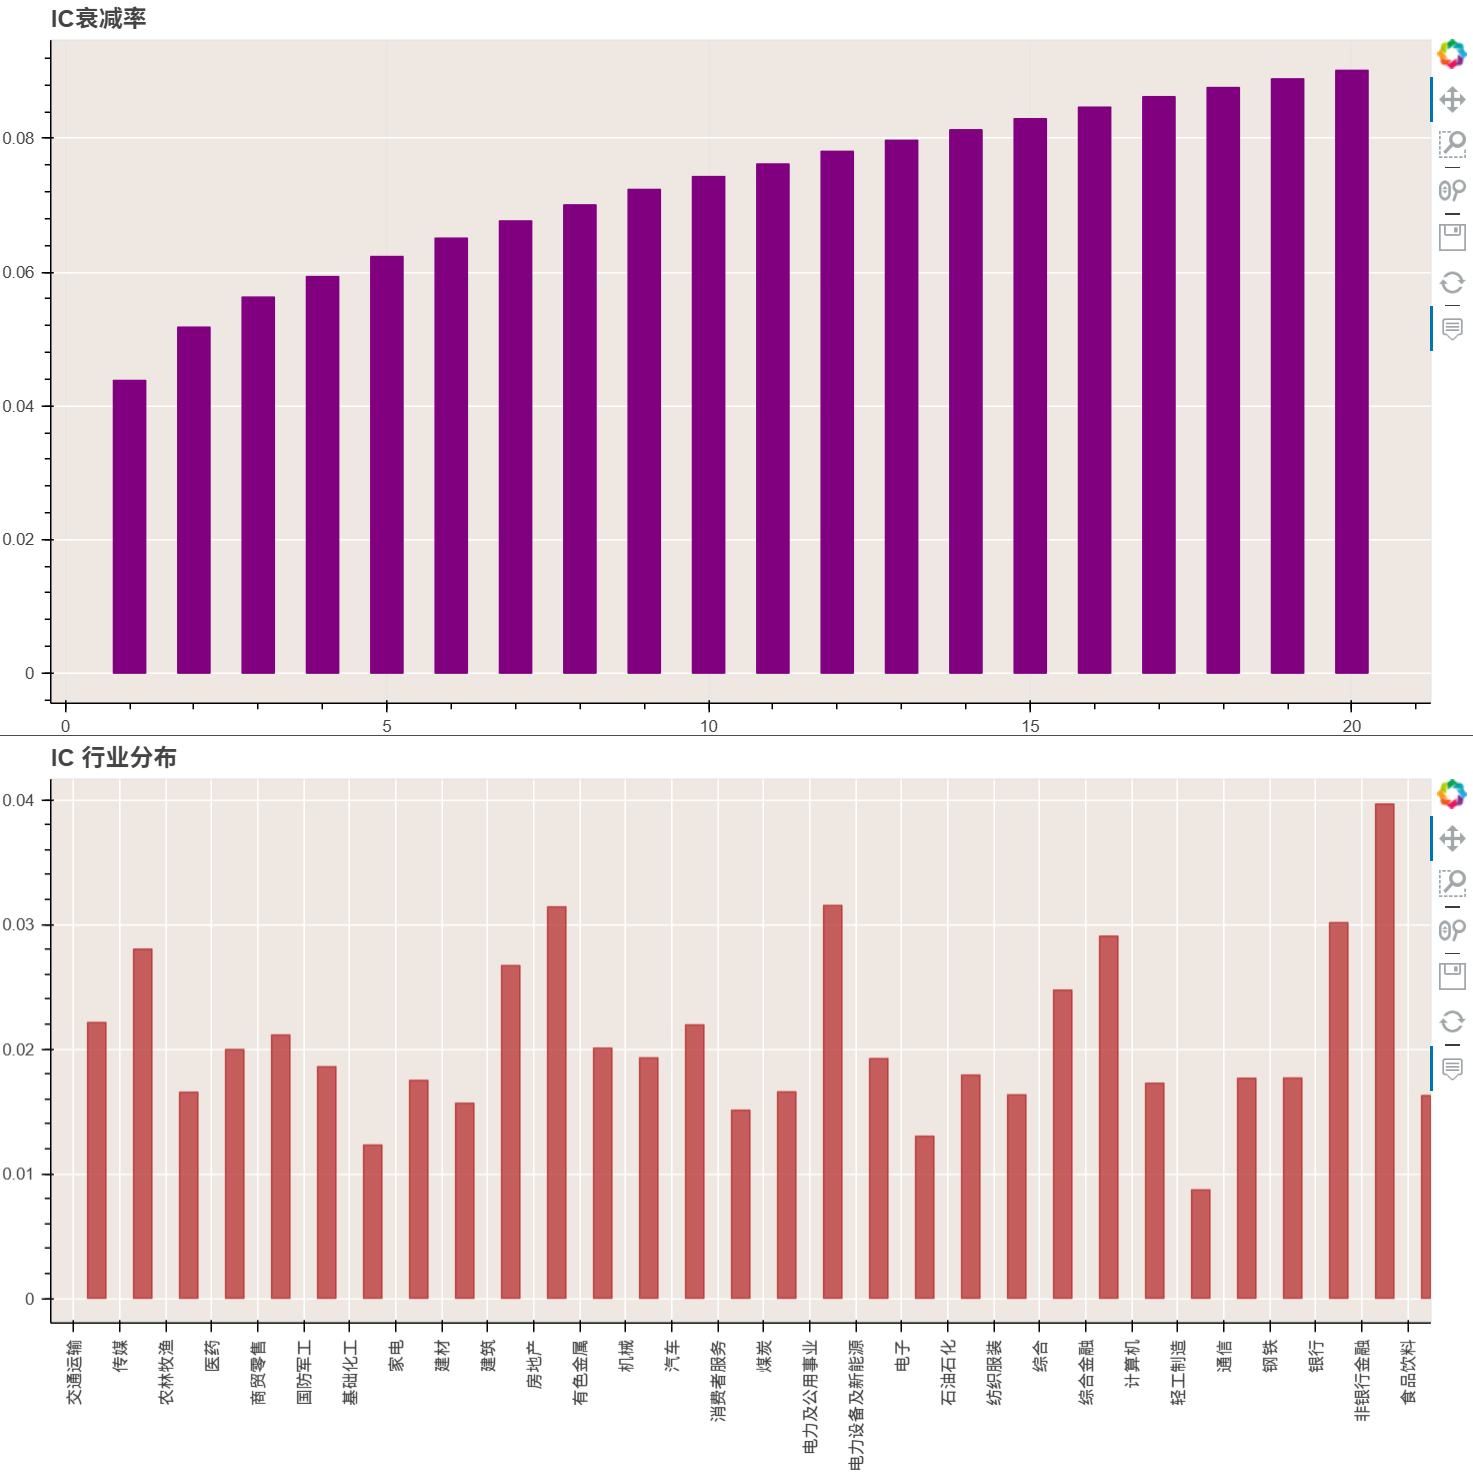

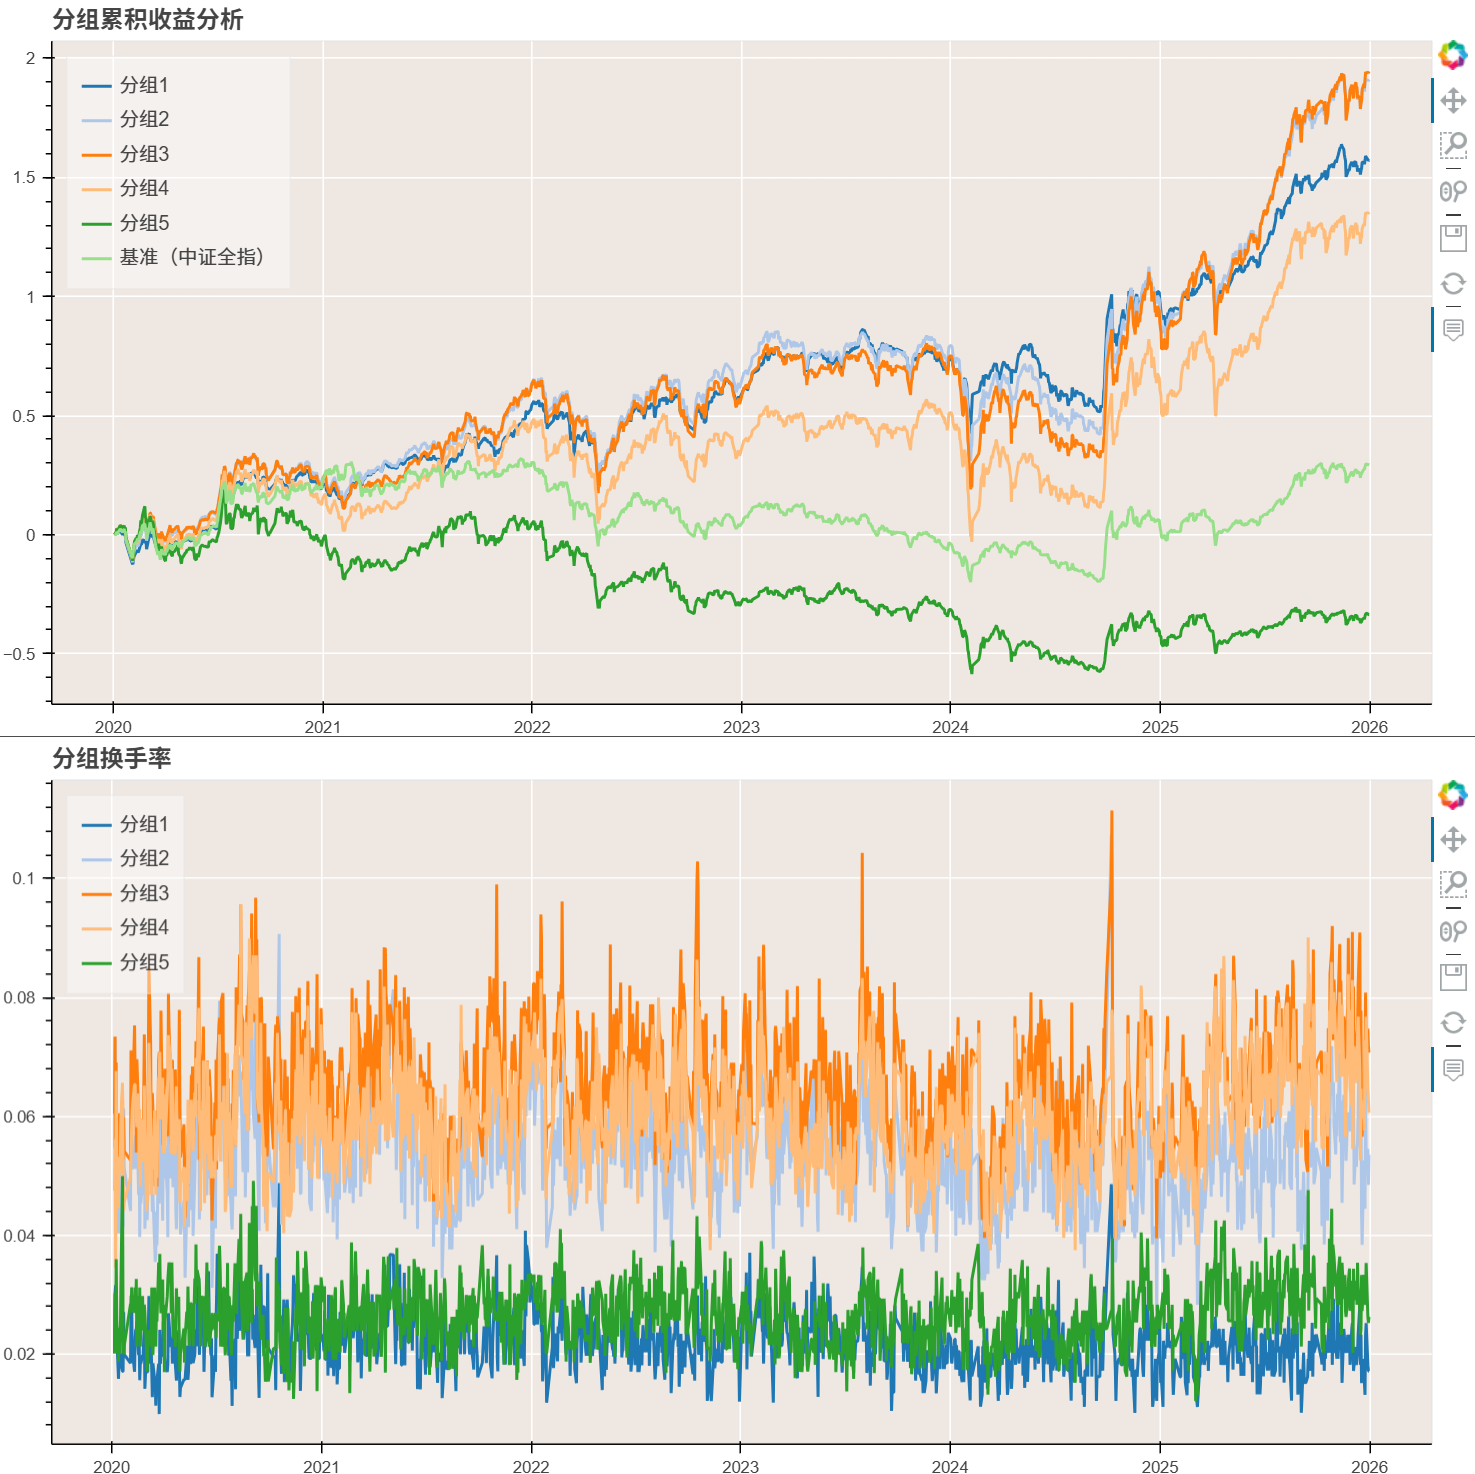

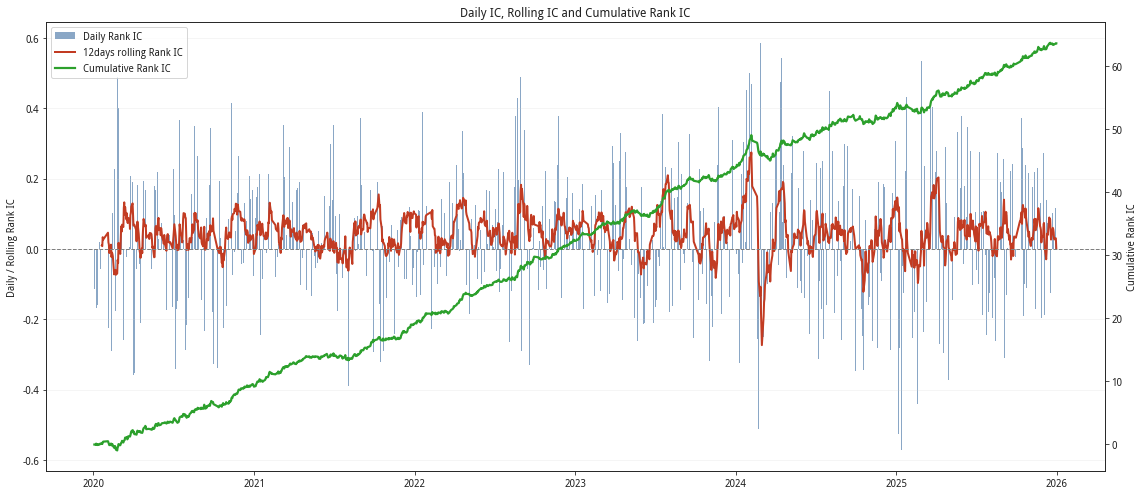

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_factor.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()